# Lending Club Loan Data Analysis — Loan Default Prediction
**Deep Learning with Keras and TensorFlow — Course-End Project**

**Objective:** Build a deep learning model that predicts whether a loan will default (`not.fully.paid = 1`) using Lending Club historical data (2007–2015).

This notebook is the guided walkthrough of the assignment. All logic lives in the `loan_default` package under `src/`, so each step here is a call into a tested module:

| Module | Responsibility |
|---|---|
| `config` | paths, preprocessing settings, model hyperparameters |
| `logging_utils` | console + file logging, timed pipeline steps |
| `data` | loading, schema validation, stratified splits |
| `features` | **Task 1** encoding, **Task 3** correlation-based dropping, log transform, scaling |
| `eda` | **Task 2** plots |
| `modeling` | **Task 4** Keras network, class weights, logistic-regression baseline |
| `evaluation` | metrics, threshold selection, evaluation plots |
| `predictor` | save / load / score new loans |
| `pipeline`, `cli` | the same workflow end-to-end: `python -m loan_default train` |

## 0. Setup

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "src"))  # not needed after `pip install -e .`

import pandas as pd

from loan_default import eda
from loan_default import evaluation as ev
from loan_default.config import Config
from loan_default.data import load_data, split_data, validate_data
from loan_default.features import FeaturePipeline, find_correlated_features, learn_categories, one_hot_encode
from loan_default.logging_utils import setup_logging
from loan_default.modeling import build_model, compute_class_weights, set_seed, train_baseline, train_model
from loan_default.predictor import LoanDefaultPredictor

cfg = Config()
log_file = setup_logging("INFO", cfg.log_dir, run_name="notebook", stream=sys.stdout)
pd.set_option("display.max_columns", 50)
print("Detailed (DEBUG) log:", log_file)

Detailed (DEBUG) log: C:\Data\09_GIT_Repos\DeepLearningProjects\DeepLearningProjects\LendingClubLoanDefault\logs\notebook_20261031_145249.log


## 1. Load and validate the data

In [2]:
df = load_data(cfg.data_path)
validate_data(df, cfg.target)
df.head()

2026-10-31 14:52:49 | INFO     | loan_default.data | Loaded 9578 rows x 14 columns from C:\Data\09_GIT_Repos\DeepLearningProjects\DeepLearningProjects\LendingClubLoanDefault\DataSet\loan_data.csv


2026-10-31 14:52:49 | INFO     | loan_default.data | No missing values


2026-10-31 14:52:49 | INFO     | loan_default.data | Target 'not.fully.paid': 16.0% positive (imbalance 5.2 : 1)


,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   str    
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), str(1)
memory usage: 1.0 MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
credit.policy,9578.0,0.804970,0.396245,0.000000,1.000000,1.000000,1.000000,1.000000e+00
int.rate,9578.0,0.122640,0.026847,0.060000,0.103900,0.122100,0.140700,2.164000e-01
installment,9578.0,319.089413,207.071301,15.670000,163.770000,268.950000,432.762500,9.401400e+02
log.annual.inc,9578.0,10.932117,0.614813,7.547502,10.558414,10.928884,11.291293,1.452835e+01
dti,9578.0,12.606679,6.883970,0.000000,7.212500,12.665000,17.950000,2.996000e+01
fico,9578.0,710.846314,37.970537,612.000000,682.000000,707.000000,737.000000,8.270000e+02
days.with.cr.line,9578.0,4560.767197,2496.930377,178.958333,2820.000000,4139.958333,5730.000000,1.763996e+04
revol.bal,9578.0,16913.963876,33756.189557,0.000000,3187.000000,8596.000000,18249.500000,1.207359e+06
revol.util,9578.0,46.799236,29.014417,0.000000,22.600000,46.300000,70.900000,1.190000e+02
inq.last.6mths,9578.0,1.577469,2.200245,0.000000,0.000000,1.000000,2.000000,3.300000e+01


**Observations**
- 9,578 loans, 13 features + target `not.fully.paid`; no missing values or duplicates.
- `purpose` is the only categorical (text) column.
- `revol.bal`, `inq.last.6mths`, `delinq.2yrs`, `pub.rec` are heavily right-skewed.

## 2. Task 1 — Feature Transformation
`purpose` is **nominal** (no natural order), so label-encoding it as 0..6 would impose a fake ordering on the network. `one_hot_encode` turns it into discrete 0/1 columns, dropping the first level (`all_other`) as the reference to avoid a perfectly collinear column. Unseen levels at prediction time are logged and encoded as the reference level.

In [5]:
categories = learn_categories(df, cfg.categorical)
print(df["purpose"].value_counts(), "\n")
print("Reference level:", categories["purpose"][0])

encoded = one_hot_encode(df, categories)
print("Encoded shape:", encoded.shape)
encoded.filter(like="purpose_").head()

purpose
debt_consolidation    3957
all_other             2331
credit_card           1262
home_improvement       629
small_business         619
major_purchase         437
educational            343
Name: count, dtype: int64 

Reference level: all_other
Encoded shape: (9578, 19)


,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,0,1,0,0,0,0
1,1,0,0,0,0,0
2,0,1,0,0,0,0
3,0,1,0,0,0,0
4,1,0,0,0,0,0


## 3. Task 2 — Exploratory Data Analysis

### 3.1 Target distribution — class imbalance

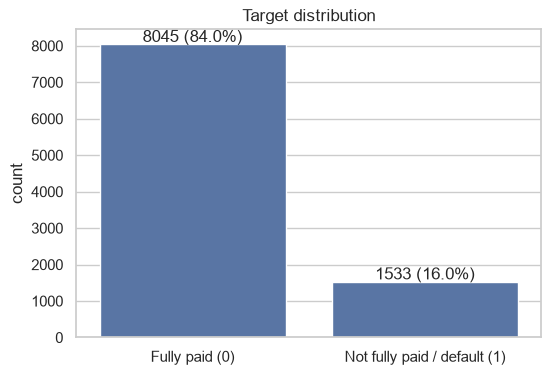

In [6]:
eda.plot_target_distribution(df);

Only **16%** of loans default (≈5.2 : 1). A model that always predicts "fully paid" would score 84% accuracy while being useless, so models are judged on **ROC-AUC, PR-AUC, recall and F1 for the default class**, and the network is trained with **class weights**.

### 3.2 Default rate by loan purpose and credit policy

purpose
small_business        0.278
educational           0.201
home_improvement      0.170
all_other             0.166
debt_consolidation    0.152
credit_card           0.116
major_purchase        0.112
Name: not.fully.paid, dtype: float64

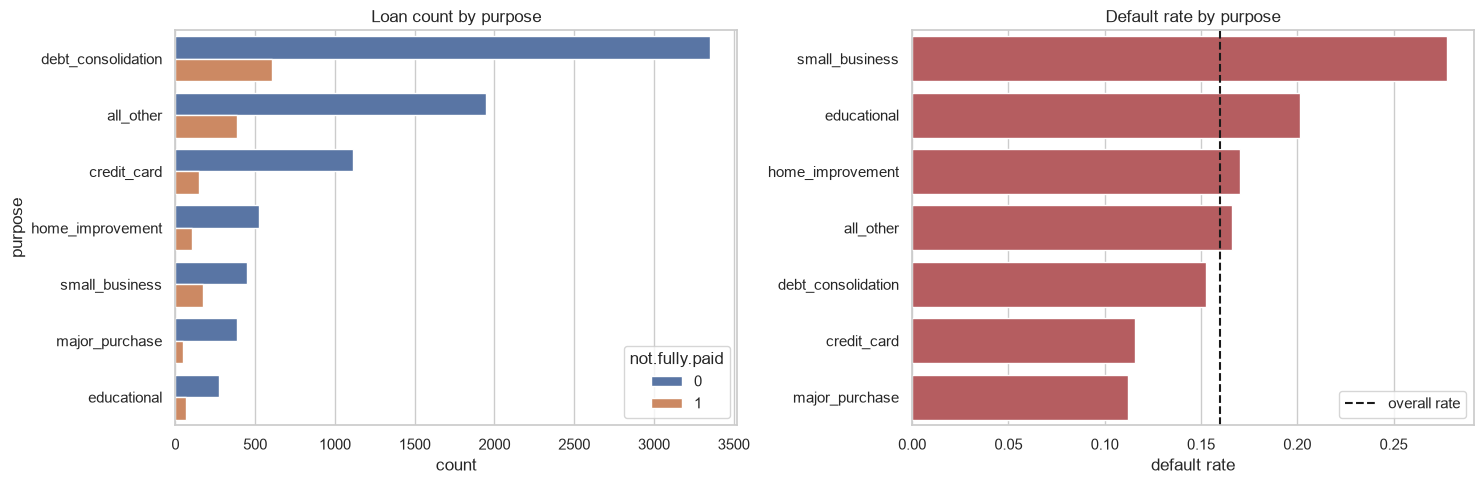

In [7]:
eda.plot_purpose(df)
eda.default_rate_by(df, "purpose").round(3)

credit.policy
0    0.278
1    0.132
Name: not.fully.paid, dtype: float64

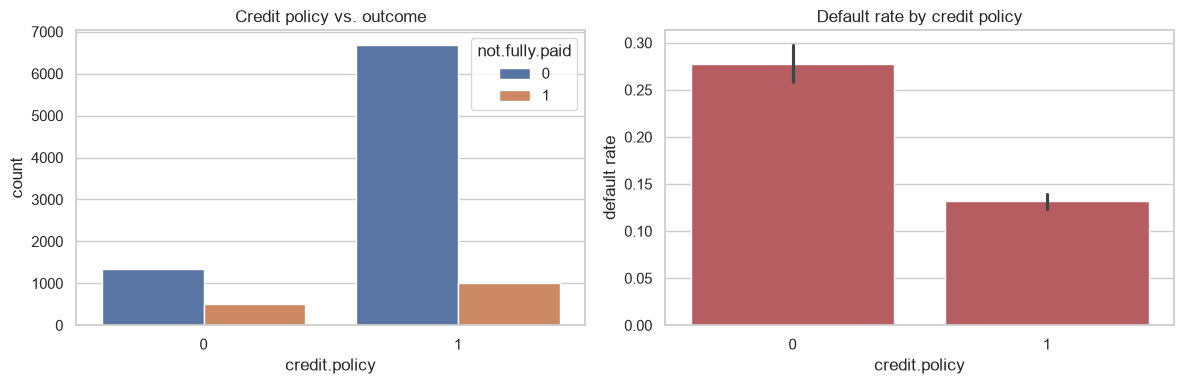

In [8]:
eda.plot_credit_policy(df)
eda.default_rate_by(df, "credit.policy").round(3)

- **Small business** loans default far more often than any other purpose; **major purchase** and **credit card** loans least.
- Borrowers who do **not** meet the credit policy default at roughly double the rate.

### 3.3 Numeric features by outcome

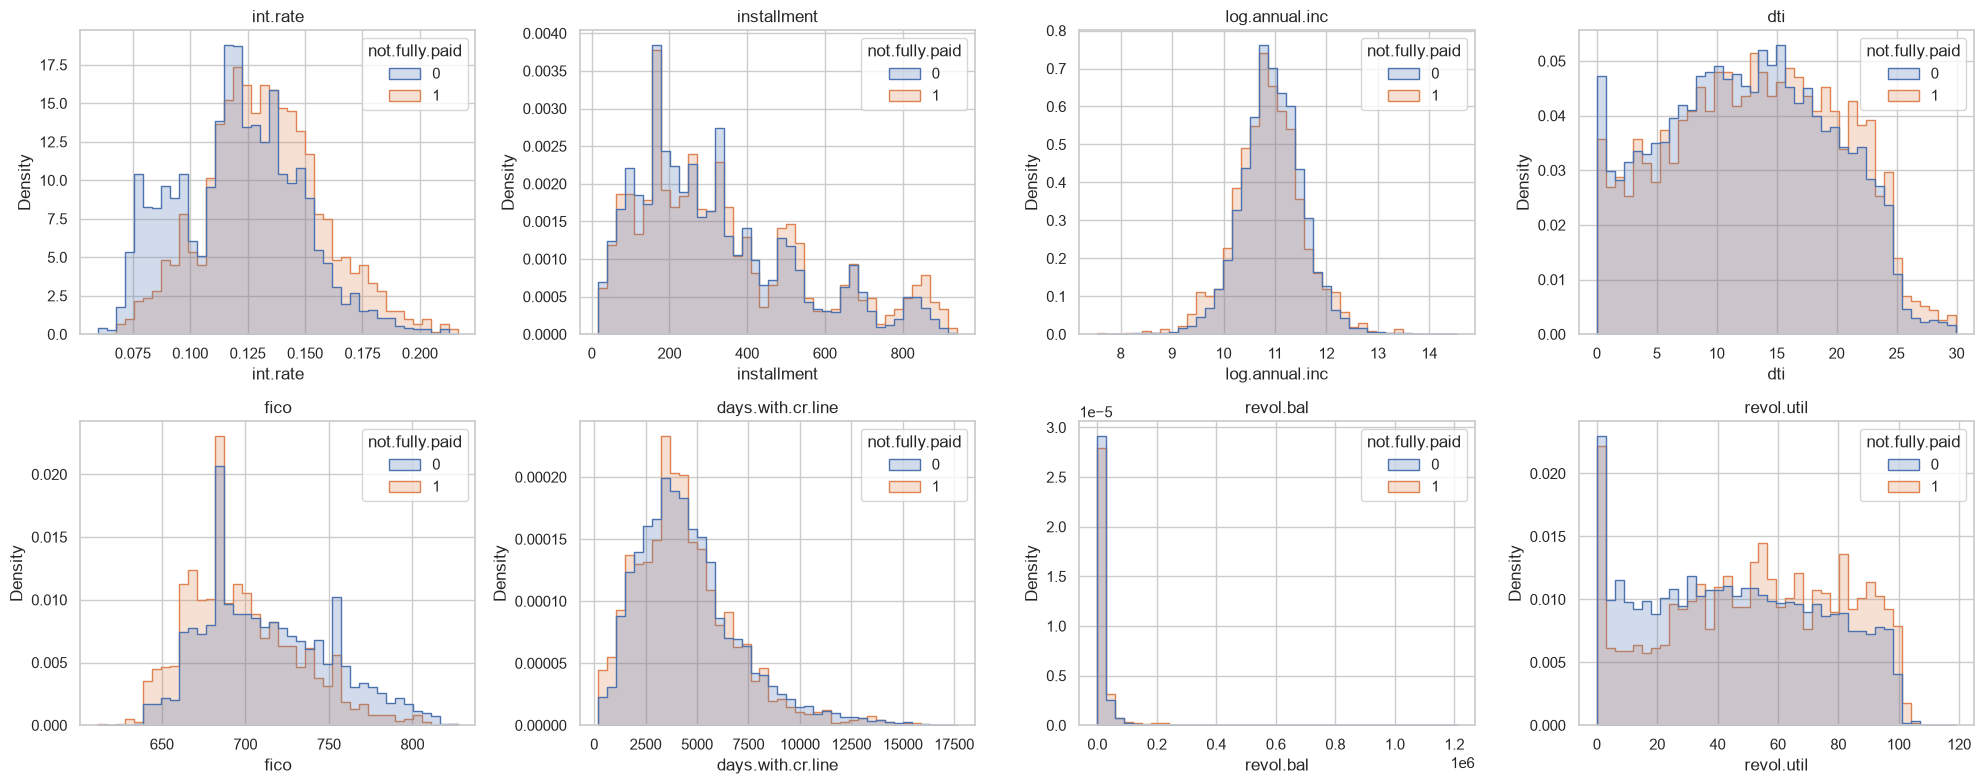

In [9]:
eda.plot_numeric_distributions(df);

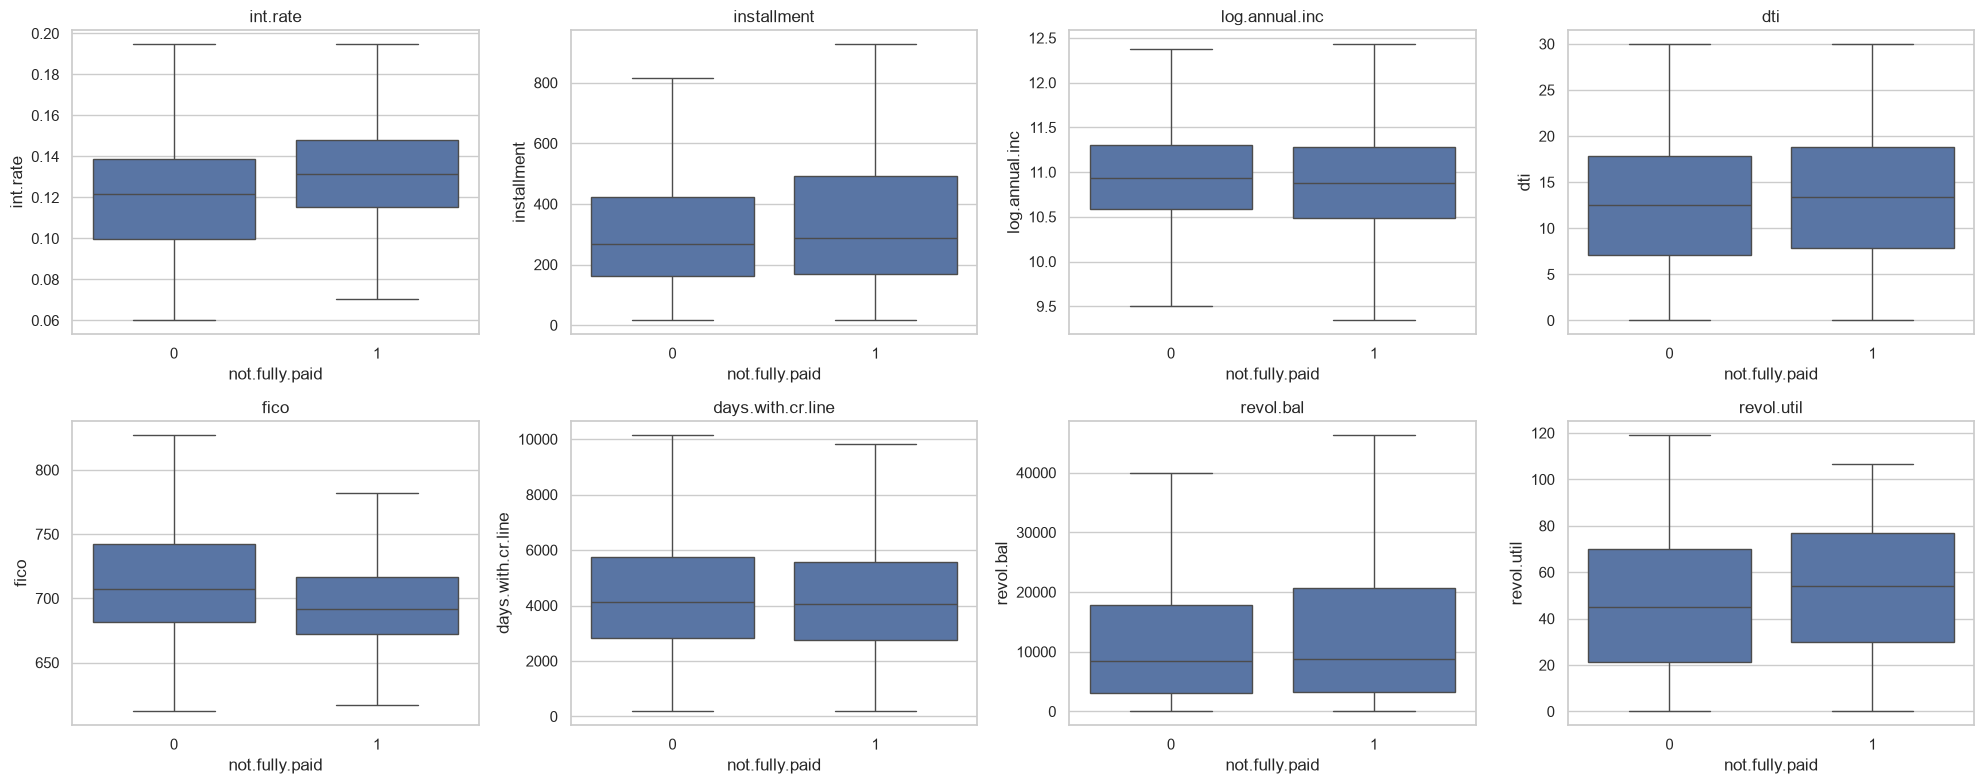

In [10]:
eda.plot_numeric_boxplots(df);

- Defaulted loans carry **higher interest rates** and come from borrowers with **lower FICO scores** — the clearest separators.
- Defaulters show slightly higher **revolving utilization** and **installments**.
- `revol.bal` is extremely right-skewed → log transform in Task 3.

### 3.4 Credit history counts

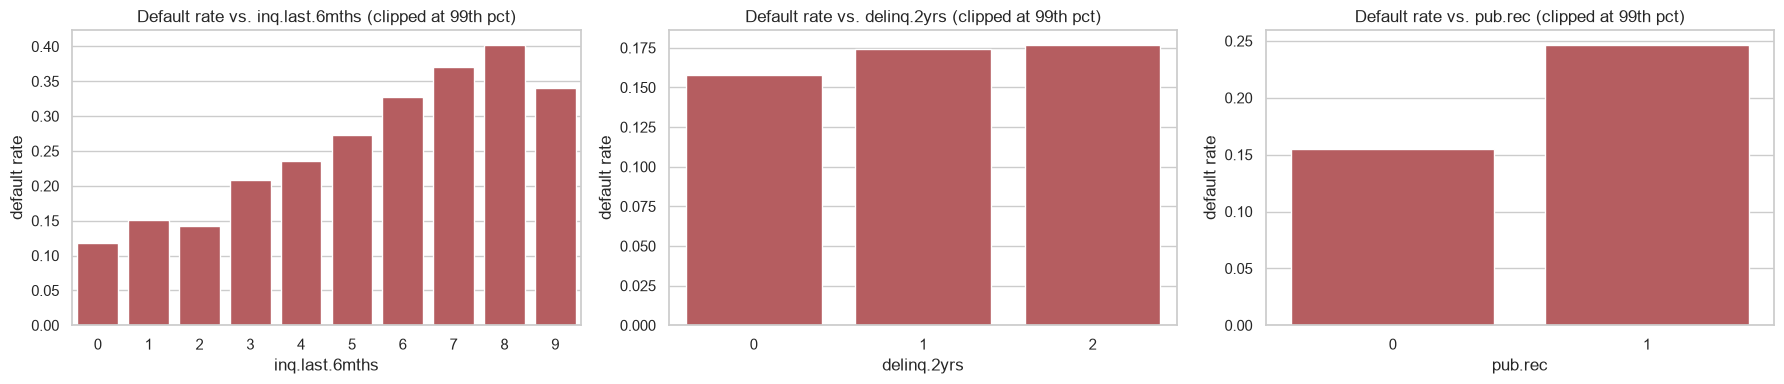

In [11]:
eda.plot_count_features(df);

Default rate climbs with the number of **recent credit inquiries** and is higher for borrowers with **public records**.

### 3.5 Interest rate vs. FICO

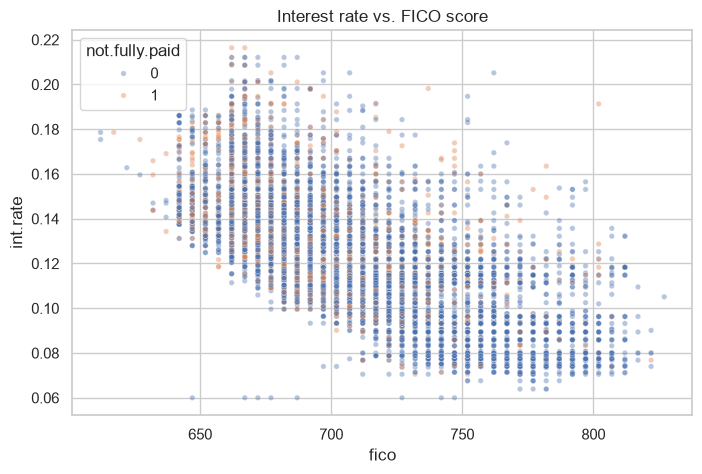

In [12]:
eda.plot_rate_vs_fico(df);

Lending Club prices risk from the FICO score, so `int.rate` and `fico` are strongly (negatively) related — addressed in Task 3.

## 4. Task 3 — Additional Feature Engineering
### 4.1 Correlation analysis
`find_correlated_features` finds pairs with |r| > 0.7 and, from each pair, drops the feature **less correlated with the target**.

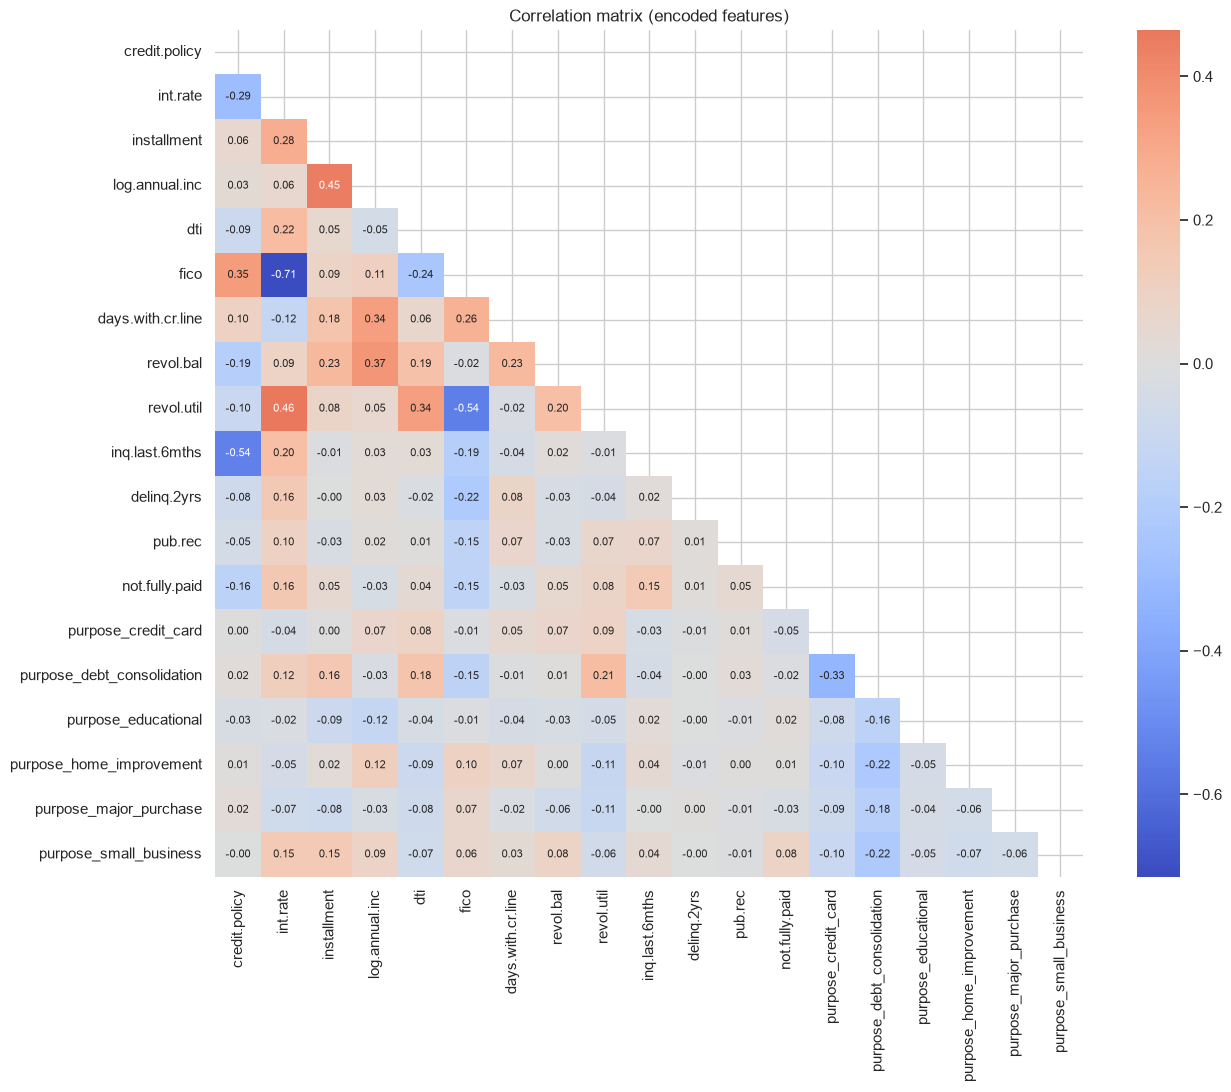

In [13]:
eda.plot_correlation_heatmap(encoded);

In [14]:
pairs, to_drop = find_correlated_features(encoded, cfg.target, cfg.corr_threshold)
pd.DataFrame(pairs, columns=["feature_a", "feature_b", "r"])

2026-10-31 14:52:54 | INFO     | loan_default.features | int.rate vs fico: r=-0.715 -> drop 'fico' (|r with target| 0.150 < 0.160)


,feature_a,feature_b,r
0,int.rate,fico,-0.714821


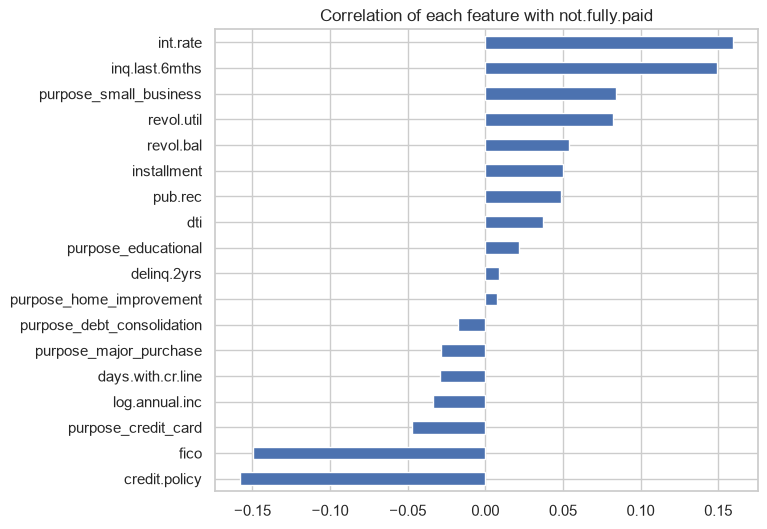

In [15]:
eda.plot_target_correlation(encoded);

Only `int.rate` / `fico` exceeds the threshold. `fico` is dropped: `int.rate` is slightly more predictive and already encodes Lending Club's FICO-based risk pricing.

> The analysis above uses the full dataset for exploration. In modeling, `FeaturePipeline` repeats this decision **on the training split only**, so no information from the test set leaks into feature selection.

### 4.2 Skew correction

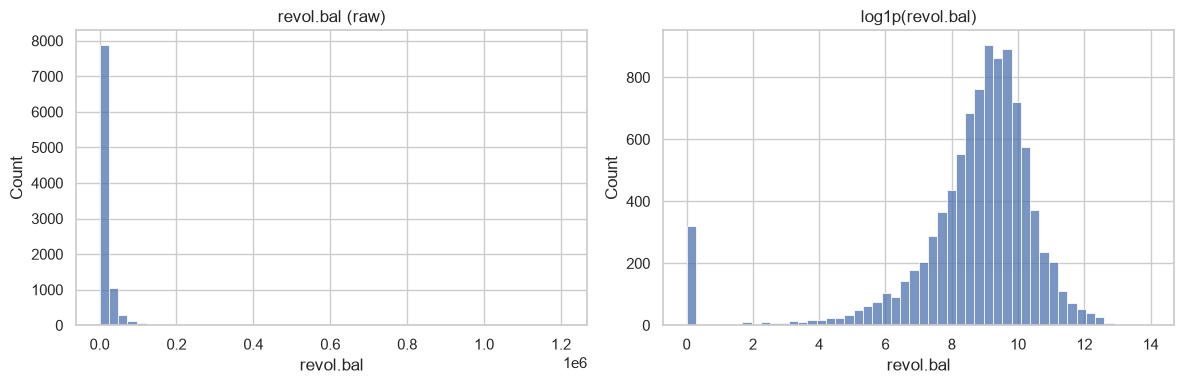

In [16]:
eda.plot_log_transform(df, "revol.bal");

`revol.bal` (0 to 1.2M) is replaced by `log1p(revol.bal)` so a few huge balances don't dominate gradient updates. (`log.annual.inc` is already log-scaled in the source data.)

## 5. Task 4 — Modeling (Keras / TensorFlow)
### 5.1 Split, fit the feature pipeline, scale
Stratified 70 / 15 / 15 split. `FeaturePipeline` learns encoding levels, correlated features to drop, imputation medians and `StandardScaler` statistics **from the training split only**, then applies them unchanged to validation and test.

In [17]:
splits = split_data(df, cfg.target, cfg.val_size, cfg.test_size, cfg.seed)
y_train, y_val, y_test = (part[cfg.target].to_numpy() for _, part in splits.items())

features = FeaturePipeline(cfg.target, cfg.categorical, cfg.log_transform, cfg.corr_threshold)
X_train = features.fit_transform(splits.train)
X_val, X_test = features.transform(splits.val), features.transform(splits.test)

print("Model features:", features.feature_names_)

2026-10-31 14:52:55 | INFO     | loan_default.data | train:  6704 rows, positive rate 0.160


2026-10-31 14:52:55 | INFO     | loan_default.data | val  :  1437 rows, positive rate 0.160


2026-10-31 14:52:55 | INFO     | loan_default.data | test :  1437 rows, positive rate 0.160


2026-10-31 14:52:55 | INFO     | loan_default.features | int.rate vs fico: r=-0.709 -> drop 'fico' (|r with target| 0.146 < 0.163)


2026-10-31 14:52:55 | INFO     | loan_default.features | Feature pipeline fitted on 6704 rows: 17 features, dropped ['fico']


Model features: ['credit.policy', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'days.with.cr.line', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_major_purchase', 'purpose_small_business', 'log.revol.bal']


### 5.2 Class imbalance and baseline
**Class weights** make each default count ~5× more than a fully paid loan in the loss, without adding synthetic rows. A class-weighted **logistic regression** gives a baseline to judge whether the deep model adds value.

In [18]:
class_weight = compute_class_weights(y_train)
baseline = train_baseline(X_train, y_train, cfg.seed)

2026-10-31 14:52:55 | INFO     | loan_default.modeling | Class weights: {0: 0.595, 1: 3.124}


2026-10-31 14:52:55 | INFO     | loan_default.modeling | Trained logistic-regression baseline on 6704 rows


### 5.3 Deep neural network
`build_model` stacks Dense → BatchNorm → Dropout blocks (64 → 32 → 16, ReLU, L2) with a sigmoid output, trained with Adam and binary cross-entropy. Training uses **EarlyStopping** on validation AUC (best weights restored) and **ReduceLROnPlateau**; progress is routed through the logger (every epoch is in the log file).

Hyperparameters (`cfg.model`) were chosen by comparing a handful of configurations on **validation** AUC; higher learning rates peaked within a few epochs and became noisy.

In [19]:
cfg.model

ModelConfig(hidden_units=(64, 32, 16), dropout=0.3, l2=0.0001, learning_rate=0.0003, batch_size=128, epochs=300, early_stopping_patience=25, reduce_lr_patience=8, reduce_lr_factor=0.5, min_lr=1e-05, log_every=10)

In [20]:
set_seed(cfg.seed)
model = build_model(X_train.shape[1], cfg.model)
model.summary()

2026-10-31 14:52:55 | INFO     | loan_default.modeling | Built model: 17 inputs, hidden units [64, 32, 16], 4225 parameters


Model: "loan_default_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,225 (16.50 KB)

 Trainable params: 4,001 (15.63 KB)

 Non-trainable params: 224 (896.00 B)

In [21]:
history = train_model(model, X_train, y_train, X_val, y_val, cfg.model, class_weight)

2026-10-31 14:52:55 | INFO     | loan_default.modeling | Training for up to 300 epochs (batch size 128, lr 3.0e-04)


2026-10-31 14:52:57 | INFO     | loan_default.modeling | Epoch   1 | auc=0.5382 loss=0.9232 pr_auc=0.1799 precision=0.173 recall=0.4865 val_auc=0.5707 val_loss=0.673 val_pr_auc=0.2331 val_precision=0.1989 val_recall=0.4522 learning_rate=0.0003


2026-10-31 14:52:59 | INFO     | loan_default.modeling | Epoch  10 | auc=0.6048 loss=0.744 pr_auc=0.221 precision=0.2045 recall=0.5527 val_auc=0.6553 val_loss=0.6373 val_pr_auc=0.2469 val_precision=0.2405 val_recall=0.5217 learning_rate=0.0003


2026-10-31 14:53:01 | INFO     | loan_default.modeling | Epoch  20 | auc=0.633 loss=0.6962 pr_auc=0.2469 precision=0.2254 recall=0.5862 val_auc=0.6542 val_loss=0.6329 val_pr_auc=0.2422 val_precision=0.244 val_recall=0.5348 learning_rate=0.0003


2026-10-31 14:53:02 | INFO     | loan_default.modeling | Epoch  30 | auc=0.6325 loss=0.6834 pr_auc=0.2522 precision=0.2176 recall=0.5517 val_auc=0.654 val_loss=0.6383 val_pr_auc=0.2422 val_precision=0.2481 val_recall=0.5565 learning_rate=0.00015


2026-10-31 14:53:04 | INFO     | loan_default.modeling | Epoch  40 | auc=0.6504 loss=0.6711 pr_auc=0.2652 precision=0.2259 recall=0.5899 val_auc=0.6527 val_loss=0.6388 val_pr_auc=0.2412 val_precision=0.2467 val_recall=0.5652 learning_rate=3.75e-05


2026-10-31 14:53:04 | INFO     | loan_default.modeling | Training loop took 9.5s


2026-10-31 14:53:04 | INFO     | loan_default.modeling | Stopped after 40 epochs; restored best epoch 15 (val_auc=0.6560, val_loss=0.6307)


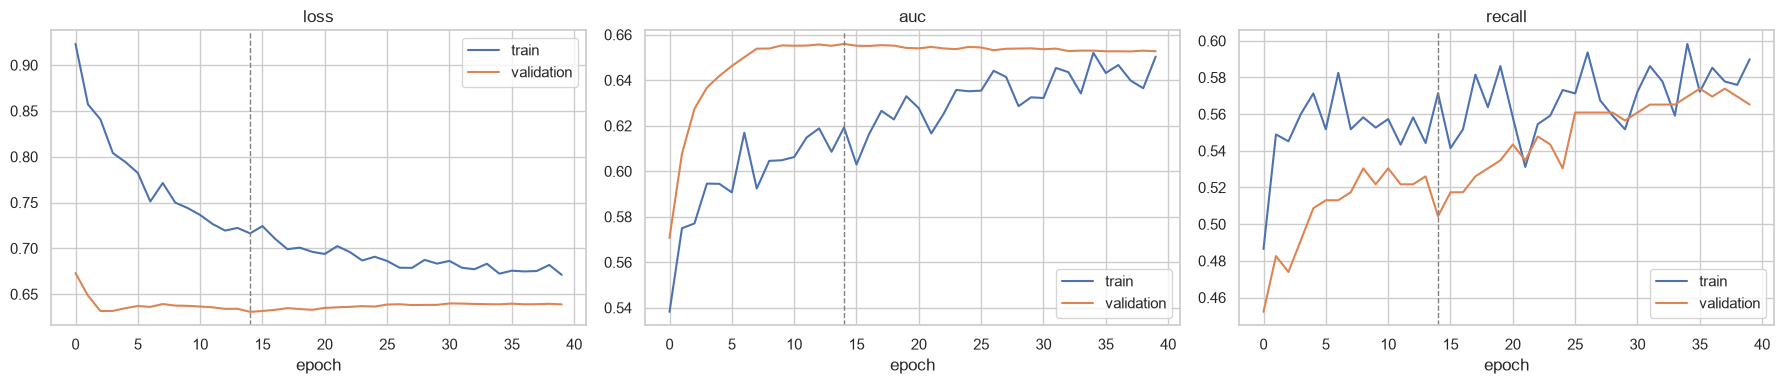

In [22]:
ev.plot_training_history(history);

### 5.4 Decision threshold
Class weights shift predicted probabilities upward, so 0.5 isn't necessarily the best cutoff. The threshold maximising F1 on the **validation** set is applied unchanged to test.

2026-10-31 14:53:05 | INFO     | loan_default.evaluation | Best threshold 0.47 (validation F1=0.3552; F1 at 0.50=0.3209)


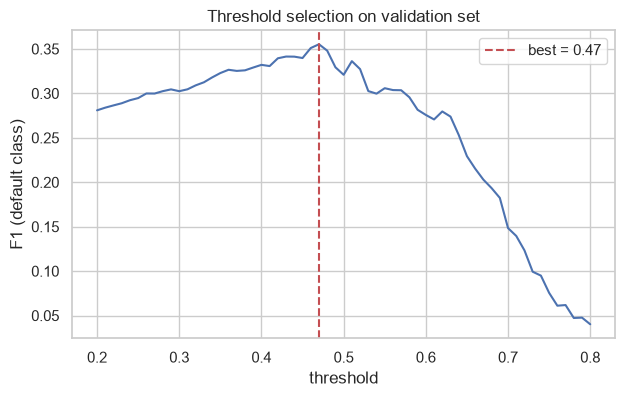

In [23]:
search = ev.choose_threshold(y_val, model.predict(X_val, verbose=0).ravel(), *cfg.threshold_grid)
ev.plot_threshold_search(search);

## 6. Evaluation on the held-out test set

In [24]:
test_proba = {
    "Logistic Regression": baseline.predict_proba(X_test)[:, 1],
    "Neural Network": model.predict(X_test, verbose=0).ravel(),
}
test_metrics = {
    "Logistic Regression": ev.compute_metrics(y_test, test_proba["Logistic Regression"], 0.5),
    "Neural Network": ev.compute_metrics(y_test, test_proba["Neural Network"], search.best),
}
for name, metrics in test_metrics.items():
    ev.log_metrics(name, metrics)
ev.comparison_table(test_metrics)

2026-10-31 14:53:05 | INFO     | loan_default.evaluation | Logistic Regression @ 0.50 | ROC-AUC 0.6566 | PR-AUC 0.3095 | precision 0.241 | recall 0.526 | F1 0.330 | accuracy 0.658


2026-10-31 14:53:05 | INFO     | loan_default.evaluation | Neural Network @ 0.47 | ROC-AUC 0.6452 | PR-AUC 0.2792 | precision 0.236 | recall 0.570 | F1 0.333 | accuracy 0.635


,threshold,roc_auc,pr_auc,precision,recall,f1,accuracy
Logistic Regression,0.50,0.6566,0.3095,0.2406,0.5261,0.3302,0.6583
Neural Network,0.47,0.6452,0.2792,0.2356,0.5696,0.3333,0.6354


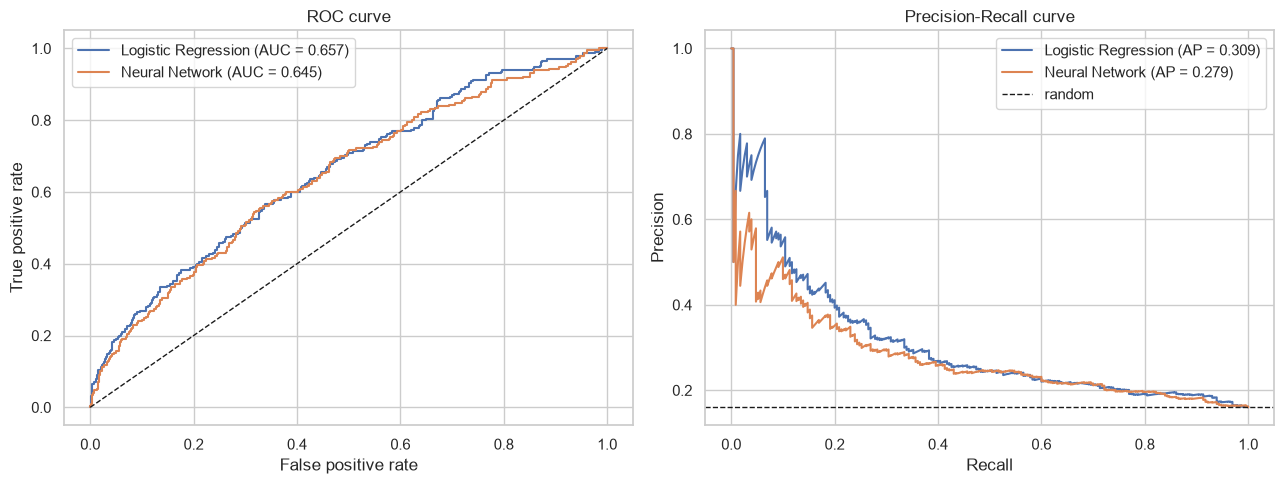

In [25]:
ev.plot_roc_pr(y_test, test_proba);

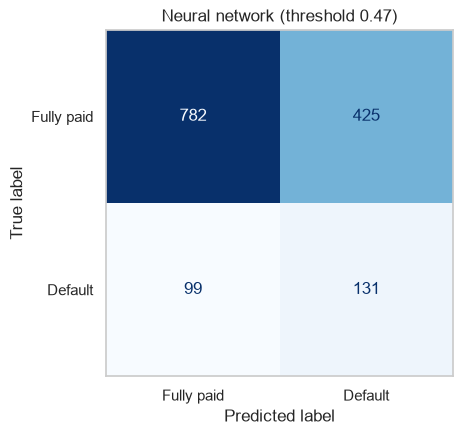

In [26]:
ev.plot_confusion_matrix(y_test, test_proba["Neural Network"], search.best, "Neural network");

### 6.1 Save and reuse the model

In [27]:
predictor = LoanDefaultPredictor(model, features, search.best)
predictor.save(cfg.artifacts_dir, {"test_metrics": test_metrics["Neural Network"]})

loaded = LoanDefaultPredictor.load(cfg.artifacts_dir)
sample = splits.test.drop(columns=cfg.target).sample(5, random_state=1)
pd.concat([sample[["purpose", "int.rate", "fico", "credit.policy"]],
           loaded.predict(sample), splits.test.loc[sample.index, cfg.target].rename("actual")], axis=1)

2026-10-31 14:53:06 | INFO     | loan_default.predictor | Saved model artefacts to C:\Data\09_GIT_Repos\DeepLearningProjects\DeepLearningProjects\LendingClubLoanDefault\models


2026-10-31 14:53:06 | INFO     | loan_default.predictor | Loaded model from C:\Data\09_GIT_Repos\DeepLearningProjects\DeepLearningProjects\LendingClubLoanDefault\models (saved 2026-10-31T14:53:06, threshold 0.47)


2026-10-31 14:53:06 | INFO     | loan_default.predictor | Scored 5 loans: 2 flagged as likely default (threshold 0.47)


,purpose,int.rate,fico,credit.policy,default_probability,predicted_default,actual
8186,debt_consolidation,0.1520,642,0,0.7305,1,0
5551,debt_consolidation,0.1114,757,1,0.3400,0,0
7546,educational,0.0676,777,1,0.2476,0,0
4265,debt_consolidation,0.0774,752,1,0.2005,0,0
3290,small_business,0.1316,692,1,0.5075,1,0


The same can be done from the command line: `python -m loan_default predict --input new_loans.csv --output scored.csv`.

## 7. Conclusions

1. **Feature transformation:** `purpose` one-hot encoded into 6 binary columns (`all_other` as reference).
2. **EDA:** the data is imbalanced (16% defaults). Default risk rises with interest rate, recent credit inquiries, revolving utilization and public records, and falls with FICO score. Small-business loans and borrowers outside the credit policy are the riskiest groups.
3. **Feature engineering:** `int.rate` / `fico` was the only pair above |r| = 0.7; `fico` was dropped. `revol.bal` was log-transformed.
4. **Modeling:** a regularized Keras MLP trained with class weights, early stopping and a validation-tuned threshold reaches test ROC-AUC ≈ 0.65 and PR-AUC ≈ 0.28 (vs. 0.16 for random guessing), and catches over half of all defaults — compared with **zero** for the naive "always fully paid" model that scores 84% accuracy.

**Limitations and next steps**
- With only 13 borrower features the signal is limited; ROC-AUC around 0.65–0.67 is typical for this dataset. The network performs **on par with (not better than) logistic regression**, suggesting mostly linear relationships with little non-linear structure to exploit.
- With ~230 defaults in the test set, differences of ±0.01 AUC are within noise; cross-validation would give a more reliable comparison.
- Possible improvements: hyperparameter search (Keras Tuner), focal loss, gradient-boosted trees for comparison, and a cost-sensitive threshold based on the real cost of a default vs. a rejected good loan.